# Milestone 2 - YOLOv8n on grid composites (Thavishka)

One of the group's Milestone 2 experiments. Pipeline: cleaned Milestone 1 photos → split-aware 640×640 grid composites with automatic YOLO labels → fine-tune COCO-pretrained YOLOv8n → test evaluation → demo detections.

| Split | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|
| Validation (best epoch, 55) | 0.914 | 0.886 | 0.935 | 0.934 |
| Test | 0.944 | 0.868 | 0.942 | 0.940 |

Trained locally on an RTX 5060 (Ultralytics 8.4, PyTorch 2.9). The outputs below are from that run.

**To re-run:** point `PROJECT` at a folder holding `data/clean/` (the cleaned Milestone 1 dataset, 73 objects, 6,942 photos at 224×224, background shots removed) and `data/clean/split.csv` (a copy is in `records/thavishka_split_m1.csv`). Existing composites and weights are reused unless `FORCE_REGENERATE` / `FORCE_RETRAIN` are set. Seed 42 throughout.

## 1. Settings

In [1]:
import os, sys, csv, random, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.system("pip install -q ultralytics")

#folder with data/clean/ (milestone 1) - outputs go to data/multi, models, runs inside it
PROJECT = Path(os.environ.get("M2_PROJECT", "/content/drive/MyDrive/ie7615-discriminative"))
CLEAN = PROJECT / "data" / "clean"
MULTI = PROJECT / "data" / "multi"
MODELS = PROJECT / "models"
RUNS = PROJECT / "runs"

SEED = 42
N_IMAGES = 1500           #70/15/15 -> 1050 / 225 / 225
SIZE = 640                #yolov8 default
LAYOUTS = [(1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]  #rows, cols -> 2 to 9 objects
BG = (128, 128, 128)

MODEL = "yolov8n.pt"
EPOCHS = 60
PATIENCE = 15
CONF = 0.25               #demo / object-level accuracy threshold
IOU_MATCH = 0.5

FORCE_REGENERATE = False  #rebuild composites even if data/multi exists
FORCE_RETRAIN = False     #retrain even if models/best_yolo.pt exists

## 2. Multi-object dataset

Each composite is a 640×640 grey canvas with a random grid layout (1×2, 1×3, 2×2, 2×3 or 3×3). Every cell gets a random photo with a random flip, brightness 0.7–1.3, contrast 0.8–1.2 and rotation ±15°, scaled to 70–100% of the cell at a random offset. The script knows where each tile goes, so the YOLO labels are written automatically.

Tiles for each split only come from the same split of the Milestone 1 train/val/test division, so no test photo is seen in training.

In [2]:
from PIL import Image, ImageEnhance


def augment(img, rng):
    if rng.random() < 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = ImageEnhance.Brightness(img).enhance(rng.uniform(0.7, 1.3))
    img = ImageEnhance.Contrast(img).enhance(rng.uniform(0.8, 1.2))
    return img.rotate(rng.uniform(-15, 15), expand=False, fillcolor=BG)


def make_one(pool, classes, rng):
    rows, cols = rng.choice(LAYOUTS)
    cell = SIZE // max(rows, cols)
    canvas = Image.new("RGB", (SIZE, SIZE), BG)
    x0 = (SIZE - cols * cell) // 2
    y0 = (SIZE - rows * cell) // 2
    labels = []
    for r in range(rows):
        for c in range(cols):
            cls = rng.choice(classes)
            img = augment(Image.open(rng.choice(pool[cls])).convert("RGB"), rng)
            s = int(cell * rng.uniform(0.7, 1.0))
            img = img.resize((s, s), Image.LANCZOS)
            x = x0 + c * cell + rng.randint(0, cell - s)
            y = y0 + r * cell + rng.randint(0, cell - s)
            canvas.paste(img, (x, y))
            #box = the whole pasted tile
            labels.append(f"{classes.index(cls)} {(x + s / 2) / SIZE:.6f} {(y + s / 2) / SIZE:.6f} {s / SIZE:.6f} {s / SIZE:.6f}")
    return canvas, labels


pools = {"train": {}, "val": {}, "test": {}}
with open(CLEAN / "split.csv", newline="") as f:
    for row in csv.DictReader(f):
        pools[row["split"]].setdefault(row["object_id"], []).append(CLEAN / row["file"])
classes = sorted(pools["train"])
print(f"{len(classes)} objects, " + ", ".join(f"{s} {sum(map(len, p.values()))} photos" for s, p in pools.items()))

counts = {"train": round(N_IMAGES * 0.7), "val": round(N_IMAGES * 0.15)}
counts["test"] = N_IMAGES - counts["train"] - counts["val"]

if FORCE_REGENERATE or not (MULTI / "data.yaml").exists():
    rng = random.Random(SEED)
    i = 0
    for split, n in counts.items():
        (MULTI / "images" / split).mkdir(parents=True, exist_ok=True)
        (MULTI / "labels" / split).mkdir(parents=True, exist_ok=True)
        for _ in range(n):
            img, labels = make_one(pools[split], classes, rng)
            img.save(MULTI / "images" / split / f"multi_{i:04d}.jpg", quality=95)
            (MULTI / "labels" / split / f"multi_{i:04d}.txt").write_text("\n".join(labels) + "\n")
            i += 1
    print("generated", counts)
else:
    print("reusing existing composites in", MULTI)

#rewritten every run so the absolute path matches this machine
names = "\n".join(f"  {k}: {c}" for k, c in enumerate(classes))
(MULTI / "data.yaml").write_text(f"path: {MULTI.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n{names}\n")
for split in counts:
    print(split, len(list((MULTI / "images" / split).glob("*.jpg"))), "images")

73 objects, train 4823 photos, val 1019 photos, test 1100 photos
reusing existing composites in C:\Users\thavi\Documents\Personal\school\projects\ie7615-discriminative\data\multi
train 1050 images
val 225 images
test 225 images


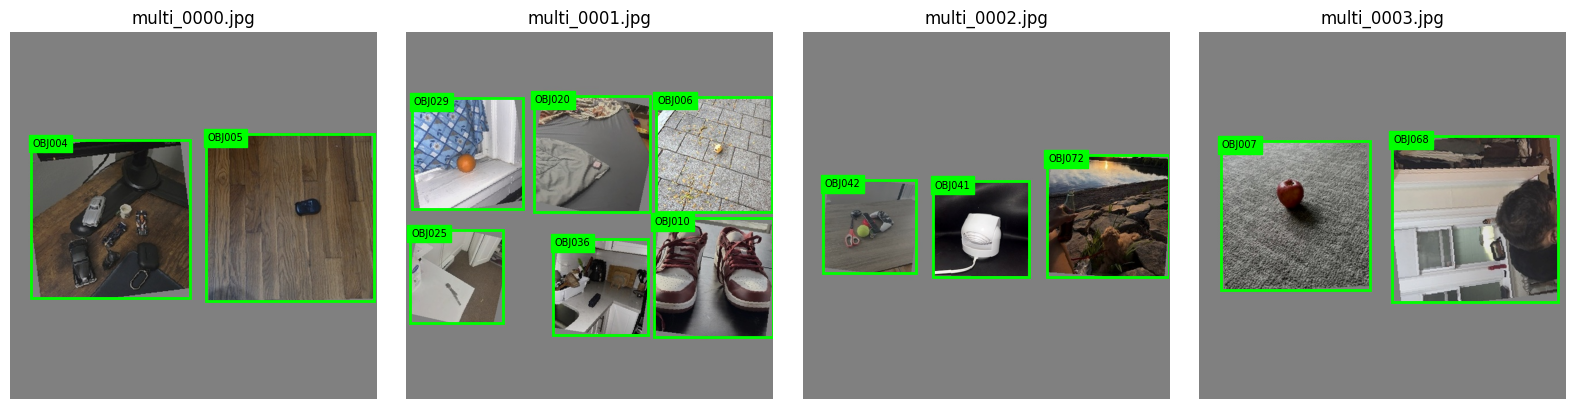

In [3]:
#ground-truth boxes drawn from the label files (only for this figure, the dataset images are clean)
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def read_labels(img_path):
    img_path = Path(img_path)
    lbl = MULTI / "labels" / img_path.parent.name / (img_path.stem + ".txt")
    out = []
    for line in lbl.read_text().strip().splitlines():
        k, xc, yc, w, h = line.split()
        xc, yc, w, h = (float(v) * SIZE for v in (xc, yc, w, h))
        out.append((int(k), xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2))
    return out


samples = sorted((MULTI / "images" / "train").glob("*.jpg"))[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, p in zip(axes, samples):
    ax.imshow(Image.open(p))
    for k, x1, y1, x2, y2 in read_labels(p):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=2))
        ax.text(x1 + 2, y1 + 12, classes[k], color="black", backgroundcolor="lime", fontsize=7)
    ax.set_title(p.name); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Training

COCO-pretrained YOLOv8n with a new 73-class head; all 3.1M parameters fine-tuned. 60 epochs at 640 px, batch 16, early stopping patience 15, seed 42. Ultralytics picked AdamW (lr 0.00013) automatically. Mosaic is off: the images are already grids of objects, and stitching four together would make each object tiny. Ultralytics keeps the weights with the best validation fitness (`best.pt`); the test split is not used in training.

In [4]:
from ultralytics import YOLO

BEST = MODELS / "best_yolo.pt"
if FORCE_RETRAIN or not BEST.exists():
    model = YOLO(MODEL)
    model.train(data=str(MULTI / "data.yaml"), epochs=EPOCHS, imgsz=SIZE, batch=16,
                patience=PATIENCE, seed=SEED, deterministic=True, workers=4,
                fliplr=0.5, mosaic=0.0,
                project=str(RUNS), name="yolov8_multi", exist_ok=True)
    MODELS.mkdir(exist_ok=True)
    shutil.copy(RUNS / "yolov8_multi" / "weights" / "best.pt", BEST)
else:
    print("reusing trained weights:", BEST)

reusing trained weights: C:\Users\thavi\Documents\Personal\school\projects\ie7615-discriminative\models\best_yolo.pt


best epoch 55: val precision 0.914  recall 0.886  mAP50 0.935  mAP50-95 0.934


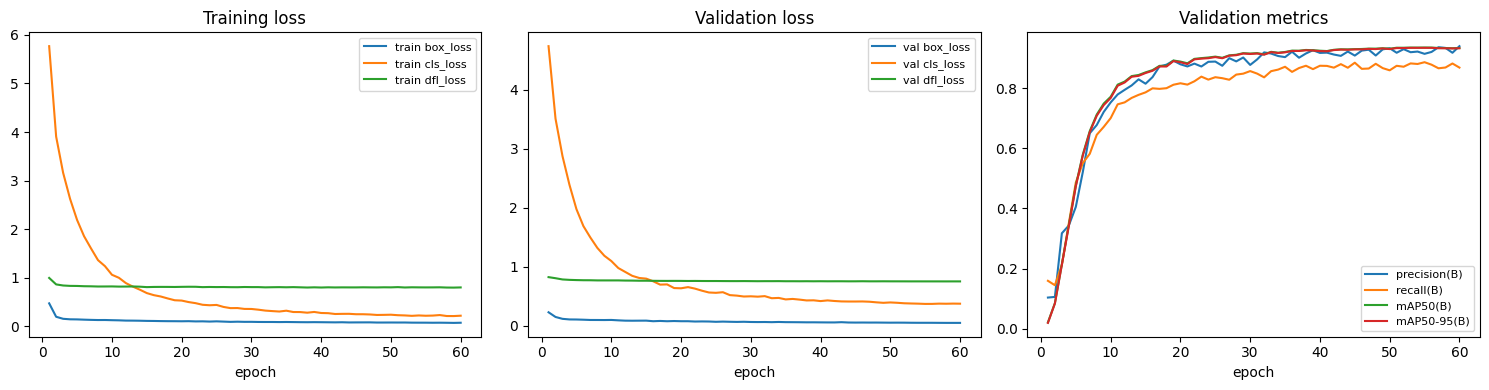

In [5]:
import pandas as pd

log = pd.read_csv(RUNS / "yolov8_multi" / "results.csv")
log.columns = log.columns.str.strip()
best_row = log.loc[(0.1 * log["metrics/mAP50(B)"] + 0.9 * log["metrics/mAP50-95(B)"]).idxmax()]  #ultralytics fitness
print(f"best epoch {int(best_row['epoch'])}: val precision {best_row['metrics/precision(B)']:.3f}  recall {best_row['metrics/recall(B)']:.3f}  "
      f"mAP50 {best_row['metrics/mAP50(B)']:.3f}  mAP50-95 {best_row['metrics/mAP50-95(B)']:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in ["box_loss", "cls_loss", "dfl_loss"]:
    axes[0].plot(log["epoch"], log[f"train/{name}"], label=f"train {name}")
    axes[1].plot(log["epoch"], log[f"val/{name}"], label=f"val {name}")
for name in ["precision(B)", "recall(B)", "mAP50(B)", "mAP50-95(B)"]:
    axes[2].plot(log["epoch"], log[f"metrics/{name}"], label=name)
for ax, t in zip(axes, ["Training loss", "Validation loss", "Validation metrics"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Test evaluation

In [6]:
best_model = YOLO(str(BEST))
m = best_model.val(data=str(MULTI / "data.yaml"), split="test", imgsz=SIZE, batch=16, workers=0,
                   project=str(RUNS), name="yolov8_test", exist_ok=True, verbose=False)
print(f"test: precision {m.box.mp:.4f}  recall {m.box.mr:.4f}  mAP50 {m.box.map50:.4f}  mAP50-95 {m.box.map:.4f}")

Ultralytics 8.4.175  Python-3.14.0 torch-2.9.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)


Model summary (fused): 73 layers, 3,150,203 parameters, 0 gradients, 8.7 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 1290.2638.7 MB/s, size: 89.4 KB)


                   all        225       1105      0.944      0.868      0.942       0.94


Speed: 0.3ms preprocess, 2.2ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to C:\Users\thavi\Documents\Personal\school\projects\ie7615-discriminative\runs\yolov8_test


test: precision 0.9442  recall 0.8677  mAP50 0.9417  mAP50-95 0.9400


### Object-level accuracy by layout

For the demo, what matters is whether each object is found with the right ID. Every test image is predicted at confidence ≥ 0.25 and each ground-truth box is matched to the best unused prediction at IoU ≥ 0.5. The layout is recovered from the object count (each layout has a different count).

In [7]:
LAYOUT_BY_COUNT = {r * c: f"{r}x{c}" for r, c in LAYOUTS}


def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)


rows = []
for p in sorted((MULTI / "images" / "test").glob("*.jpg")):
    gt = read_labels(p)
    r = best_model.predict(str(p), conf=CONF, imgsz=SIZE, verbose=False)[0]
    preds = list(zip(r.boxes.cls.int().tolist(), r.boxes.xyxy.tolist()))
    used = set()
    for k, *box in gt:
        cands = [(iou(box, pb), j) for j, (_, pb) in enumerate(preds) if j not in used]
        best_iou, j = max(cands, default=(0, None))
        if best_iou >= IOU_MATCH:
            used.add(j)
            status = "correct" if preds[j][0] == k else "wrong id"
        else:
            status = "missed"
        rows.append({"layout": LAYOUT_BY_COUNT[len(gt)], "status": status})

res = pd.DataFrame(rows)
table = res.groupby("layout")["status"].value_counts().unstack(fill_value=0)
table.loc["all"] = table.sum()
table["objects"] = table.sum(axis=1)
table["accuracy"] = (table["correct"] / table["objects"]).round(3)
table

status,correct,missed,wrong id,objects,accuracy
layout,,,,,
1x2,86,7,7,100,0.860
1x3,106,7,7,120,0.883
2x2,139,2,3,144,0.965
2x3,267,9,24,300,0.890
3x3,386,26,29,441,0.875
all,984,51,70,1105,0.890


## 5. Demo inference

`detect()` returns every object's ID, confidence and box (x1, y1, x2, y2 in pixels of the 640×640 image). Two unseen test images:

multi_1276.jpg: 8 objects found
  OBJ010  conf 1.00  box x1=437 y1=445 x2=615 y2=623
  OBJ012  conf 1.00  box x1=214 y1=426 x2=425 y2=638
  OBJ008  conf 1.00  box x1=432 y1=8 x2=620 y2=196
  OBJ011  conf 0.99  box x1=458 y1=232 x2=635 y2=408
  OBJ069  conf 0.99  box x1=6 y1=469 x2=162 y2=625
  OBJ057  conf 0.96  box x1=234 y1=6 x2=423 y2=195
  OBJ025  conf 0.57  box x1=4 y1=213 x2=213 y2=422
  OBJ046  conf 0.27  box x1=1 y1=3 x2=207 y2=210
  ground truth: ['OBJ008', 'OBJ010', 'OBJ011', 'OBJ012', 'OBJ012', 'OBJ046', 'OBJ052', 'OBJ057', 'OBJ069']
multi_1300.jpg: 2 objects found
  OBJ020  conf 0.99  box x1=14 y1=176 x2=314 y2=476
  OBJ027  conf 0.53  box x1=398 y1=187 x2=625 y2=415
  ground truth: ['OBJ020', 'OBJ027']


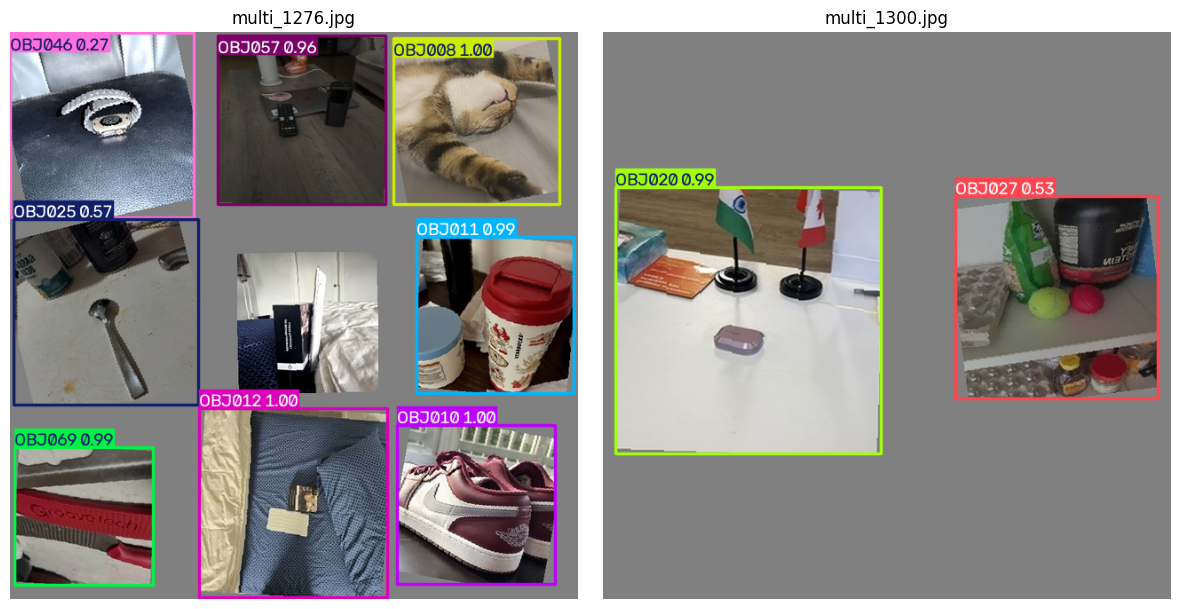

In [8]:
def detect(image_path, conf=CONF):
    r = best_model.predict(str(image_path), conf=conf, imgsz=SIZE, verbose=False)[0]
    print(f"{Path(image_path).name}: {len(r.boxes)} objects found")
    for cls, c, (x1, y1, x2, y2) in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()):
        print(f"  {r.names[int(cls)]}  conf {c:.2f}  box x1={x1:.0f} y1={y1:.0f} x2={x2:.0f} y2={y2:.0f}")
    print("  ground truth:", sorted(classes[k] for k, *_ in read_labels(image_path)))
    return r


fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, name in zip(axes, ["multi_1276.jpg", "multi_1300.jpg"]):
    r = detect(MULTI / "images" / "test" / name)
    ax.imshow(r.plot()[:, :, ::-1]); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Limitations

- Each object sits in its own tile on a plain grey background and its box is the whole tile, so the model never sees overlap or clutter. That is why mAP@0.5:0.95 is almost equal to mAP@0.5; localization on real multi-object photos would be noticeably worse.
- Boxes are loose when the object fills only part of its photo, since the box covers the whole tile.
- Most errors are missed objects (recall 0.87) rather than wrong IDs.
- Next steps: paste cut-out objects onto real backgrounds (as in `generate_dataset.ipynb`), test on real multi-object photos, and compare against YOLOv8s.